# Reproducing the figures and tables

**Order-weight decomposition unifies the interpretation, response and sampling bias of multivariate information measures**
G. Menesse, A. Roig, M. Neri, A. Liardi, P.A.M. Mediano, J.J. Torres and H. J. Jensen

This notebook reproduces every computed figure and table of the main text and the Supplementary Information (SI). Each section names the figure or table it produces, the equations of the paper it uses, and the numbers quoted in the text that it checks.

* The shared functions live in the package `orderweights/` (one module per topic). The notebook contains the plotting code and the calls.
* Figures are written to `figures/` (PNG and PDF) and tables to `tables/` (LaTeX rows and CSV).
* The Monte Carlo simulations behind the bias figures and tables are stored in `results/`. With `RECOMPUTE = False` the notebook reads them and runs in about a minute. With `RECOMPUTE = True` it runs every simulation again, with the seeds that produced the published numbers (about 5 to 10 minutes on a laptop).

Not produced here: Fig. 1 (schematic illustration), Table 1 (definitions of the measures), and panel (a) of Fig. 3 (schematic of the slice).

In [33]:
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "orderweights").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))          # so that `import orderweights` works without installing the package

import itertools as it
from math import comb, log
from fractions import Fraction as F

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap, LogNorm, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerTuple

import orderweights as ow
from orderweights import measures as M, bias as B, gaussian as G, paths, fourier, dyadic
from orderweights.slice import Slice, GEOMETRY, targets
from orderweights.cache import cached, FIGURES, TABLES

RECOMPUTE = False               # True: run all simulations again instead of reading results/
ow.cache.RECOMPUTE = RECOMPUTE
FIGURES.mkdir(exist_ok=True); TABLES.mkdir(exist_ok=True)

cm = 1 / 2.54
INK, GRID, FIRST = "black", "#e4e3dd", "#d1495b"
plt.rcParams.update({"font.family": "serif", "mathtext.fontset": "cm", "font.size": 9})

def save(fig, name, dpi=300):
    for ext in ("png", "pdf"):
        fig.savefig(FIGURES / f"{name}.{ext}", dpi=dpi, bbox_inches="tight")

def save_table(df, name, floatfmt=None):
    df.to_csv(TABLES / f"{name}.csv", index=False)
    with open(TABLES / f"{name}.tex", "w") as f:
        f.write(df.to_latex(index=False, float_format=floatfmt))

## 1. Order weights of common measures (Fig. 2)

Order weights $\lambda_m=-\sum_{k\ge m}c_k\binom{N-m}{k-m}$ (main text, Eq. lam_general) of the measures of Table 1, and of Han's basis elements $u_k$. We first check the closed forms of Eq. (spectra) exactly, with rational arithmetic.

In [34]:
def closed_form(name, N, m):
    return {"TC": 1, "DTC": m - 1, "Sigma": m, "Omega": 2 - m, "coI": (-1) ** N * (m == N),
            "TSE": F((N + 1) * (m - 1), 2 * (m + 1))}[name]

for N in range(3, 13):
    for name in ("TC", "DTC", "Sigma", "Omega", "coI", "TSE"):
        lam = M.order_weights(M.c_measure(name, N))
        assert lam[0] == 0 and all(lam[m - 1] == closed_form(name, N, m) for m in range(2, N + 1))
    for k in range(1, N):
        lam = M.order_weights(M.c_u(N, k))
        assert all(lam[m - 1] == F(comb(k - 1, m - 2), comb(N, m)) for m in range(2, N + 1))
        assert M.coefficients(lam) == M.c_u(N, k)          # Eq. c-from-lambda inverts Eq. lam_general
print("Eq. (spectra) verified exactly for N = 3..12")

Eq. (spectra) verified exactly for N = 3..12


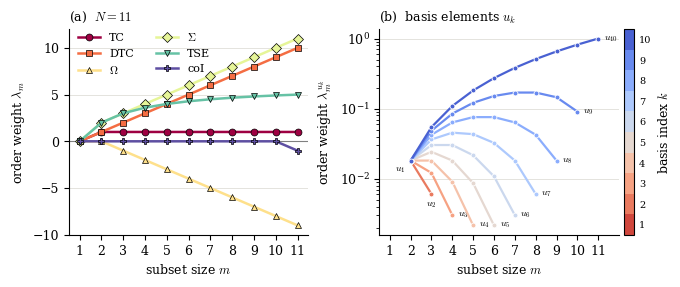

In [35]:
N = 11
ms = np.arange(1, N + 1)
series = [("TC", "TC", "o"), ("DTC", "DTC", "s"), (r"$\Omega$", "Omega", "^"), (r"$\Sigma$", "Sigma", "D"),
          ("TSE", "TSE", "v"), ("coI", "coI", "P")]
cols = plt.cm.Spectral(np.linspace(0, 1, len(series)))

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(17 * cm, 7 * cm), gridspec_kw=dict(width_ratios=[1, 1]),
                              constrained_layout=True)
ax.axhline(0, color="0.5", lw=0.8)
for (label, key, mk), col in zip(series, cols):
    lam = [float(x) for x in M.order_weights(M.c_measure(key, N))]
    ax.plot(ms, lam, color=col, lw=1.8, marker=mk, ms=5, mec=INK, mew=0.5, label=label)
ax.set_xlabel(r"subset size $m$"); ax.set_ylabel(r"order weight $\lambda_m$")
ax.set_xticks(ms); ax.grid(axis="y", color=GRID, lw=0.7); ax.set_axisbelow(True)
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.legend(frameon=False, fontsize=8, ncol=2, loc=(0.02,0.75))
ax.set_title(rf"(a)  $N={N}$", loc="left", fontsize=9)

# (b) one profile per basis element u_k, lambda_m = C(k-1, m-2) / C(N, m) for 2 <= m <= k+1,
#     on a logarithmic scale so that all of them fit in one panel
ks = np.arange(1, N)
kcols = plt.cm.coolwarm_r(np.linspace(0.08, 0.95, len(ks)))      # one colour per k
for k, col in zip(ks, kcols):
    m = np.arange(2, k + 2)
    lam = np.array([comb(k - 1, mm - 2) / comb(N, mm) for mm in m])
    ax2.plot(m, lam, color=col, lw=1.6, marker="o", ms=3.5, mec="white", mew=0.6, zorder=3)
    off, ha = {1: ((-4, -7), "right"), 2: ((0, -8), "center")}.get(k, ((4, 0), "left"))
    ax2.annotate(rf"$u_{{{k}}}$", (m[-1], lam[-1]), xytext=off, textcoords="offset points",
                 va="center", ha=ha, fontsize=7)
ax2.set_yscale("log")
ax2.set_xticks(ms); ax2.set_xlim(0.5, N + 1)
ax2.set_xlabel(r"subset size $m$"); ax2.set_ylabel(r"order weight $\lambda_m^{u_k}$")
ax2.grid(axis="y", color=GRID, lw=0.7); ax2.set_axisbelow(True)
for s in ("top", "right"): ax2.spines[s].set_visible(False)
kmap = ListedColormap(kcols)                                      # discrete colorbar, same colours as the lines
cb = fig.colorbar(plt.cm.ScalarMappable(cmap=kmap, norm=BoundaryNorm(np.arange(0.5, N + 0.5), kmap.N)),
                  ax=ax2, ticks=ks, pad=0.02)
cb.ax.minorticks_off(); cb.ax.tick_params(length=0, labelsize=7); cb.set_label(r"basis index $k$")
ax2.set_title(r"(b)  basis elements $u_k$", loc="left", fontsize=9)
save(fig, "Figure_2_some_orderweights")
plt.show()

## 2. Fourier components of Boolean rules (Methods figure fourier-rules) and SI Table S1

Coefficients $\hat\rho(\mathbf r)=\mathbb E_{\mathbb P}[\chi_{\mathbf r}]$ of the relative deviation from uniformity (Methods, Eq. rho) for $N=4$ binary variables. Each panel reports $\|\rho\|_\infty$ and $\chi^2(\mathbb P\|\mathbb U)=\sum_{\mathbf r\ne\mathbf 0}|\hat\rho(\mathbf r)|^2$.

(a) {'4': 0.75, '14': 0.25, '24': 0.25, '34': 0.25, '124': -0.25, '134': -0.25, '234': -0.25, '1234': 0.25}
(b) {'4': -0.75, '14': 0.25, '24': 0.25, '34': 0.25, '124': 0.25, '134': 0.25, '234': 0.25, '1234': 0.25}
(c) {'14': 0.5, '24': 0.5, '34': 0.5, '1234': -0.5}
(d) {'1234': 1.0}
(e) {'12': 1.0, '34': 1.0, '1234': 1.0}
(f) {'12': 1.0, '13': 1.0, '14': 1.0, '23': 1.0, '24': 1.0, '34': 1.0, '1234': 1.0}


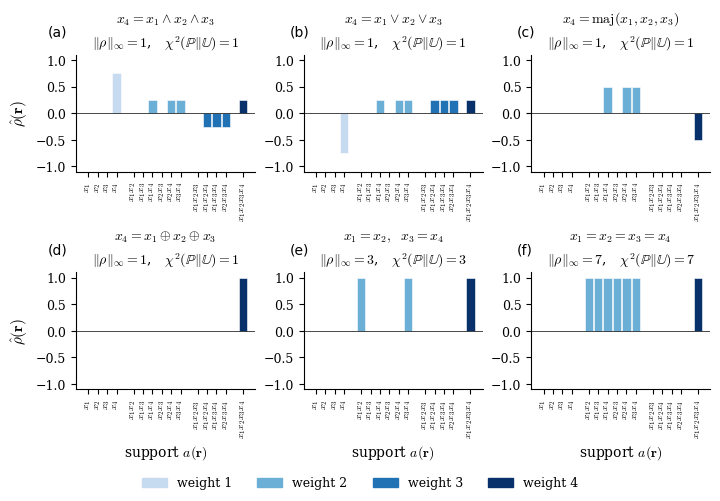

In [36]:
N = 4
RULES = [(r"$x_4=x_1\wedge x_2\wedge x_3$",   fourier.from_function(lambda a, b, c: a and b and c)),
         (r"$x_4=x_1\vee x_2\vee x_3$",       fourier.from_function(lambda a, b, c: a or b or c)),
         (r"$x_4=\mathrm{maj}(x_1,x_2,x_3)$", fourier.from_function(lambda a, b, c: a + b + c >= 2)),
         (r"$x_4=x_1\oplus x_2\oplus x_3$",   fourier.from_function(lambda a, b, c: (a + b + c) % 2)),
         (r"$x_1=x_2,\ \ x_3=x_4$",           fourier.from_constraints(lambda x: x[0] == x[1] and x[2] == x[3])),
         (r"$x_1=x_2=x_3=x_4$",               fourier.from_constraints(lambda x: len(set(x)) == 1))]
SUP = fourier.supports(N)
WCOL = {1: "#c6dbef", 2: "#6baed6", 3: "#2171b5", 4: "#08306b"}

fig, axes = plt.subplots(2, 3, figsize=(18 * cm, 12.5 * cm), constrained_layout=True)
for k, (ax, (title, P)) in enumerate(zip(axes.ravel(), RULES)):
    vals = np.array([fourier.rho_hat(P, a) for a in SUP])
    pos, x = [], 0.0
    for j, a in enumerate(SUP):
        if j and len(a) != len(SUP[j - 1]): x += 0.8
        pos.append(x); x += 1.0
    ax.bar(pos, vals, width=0.9, color=[WCOL[len(a)] for a in SUP], edgecolor="white", linewidth=0.4)
    ax.axhline(0, color="k", lw=0.5)
    ax.set_xticks(pos); ax.set_xticklabels(["$" + "".join(f"x_{i+1}" for i in a) + "$" for a in SUP], rotation=90, fontsize=7)
    ax.set_ylim(-1.1, 1.1); ax.set_yticks([-1, -0.5, 0, 0.5, 1])
    if k % 3 == 0: ax.set_ylabel(r"$\hat\rho(\mathbf{r})$", fontsize=11)
    rho = P * 2 ** N - 1
    ax.set_title(title + "\n" + rf"$\|\rho\|_\infty={np.abs(rho).max():.0f}$,   $\chi^2(\mathbb{{P}}\|\mathbb{{U}})={np.sum(vals**2):.0f}$",
                 fontsize=10, linespacing=1.5)
    ax.text(-0.16 if k % 3 == 0 else -0.08, 1.16, f"({'abcdef'[k]})", transform=ax.transAxes, fontsize=10, fontfamily="sans-serif")
    if k >= 3: ax.set_xlabel(r"support $a(\mathbf{r})$", fontsize=10)
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
    print(f"({'abcdef'[k]})", {"".join(str(i + 1) for i in a): round(float(v), 3) for a, v in zip(SUP, vals) if abs(v) > 1e-12})
fig.legend([plt.Rectangle((0, 0), 1, 1, color=WCOL[m]) for m in WCOL], [f"weight {m}" for m in WCOL],
           ncol=4, frameon=False, fontsize=9, loc="outside lower center")
save(fig, "Figure_6_Fourier_decomposition_some_rules")
plt.show()

# in (e) the weight-4 component is the product of the two weight-2 components
P = RULES[4][1]
assert np.isclose(fourier.rho_hat(P, (0, 1, 2, 3)), fourier.rho_hat(P, (0, 1)) * fourier.rho_hat(P, (2, 3)))

In [37]:
# SI Table S1: values of the characters chi_r(x) = (-1)^{r.x} for N = 3 Boolean variables
states, table = fourier.character_table(3)
lab = lambda v: "(" + "".join(map(str, v)) + ")"
rows = [[lab(r)] + ["+" if s > 0 else "-" for s in table[r]] + [sum(r)] for r in states]
tab1 = pd.DataFrame(rows, columns=["r \\ x"] + [lab(x) for x in states] + ["wt(r)"])
save_table(tab1, "Tab_1_characters")
print(tab1.to_string(index=False))

r \ x (000) (001) (010) (011) (100) (101) (110) (111)  wt(r)
(000)     +     +     +     +     +     +     +     +      0
(001)     +     -     +     -     +     -     +     -      1
(010)     +     +     -     -     +     +     -     -      1
(011)     +     -     -     +     +     -     -     +      2
(100)     +     +     +     +     -     -     -     -      1
(101)     +     -     +     -     -     +     -     +      2
(110)     +     +     -     -     -     -     +     +      2
(111)     +     -     -     +     -     +     +     -      3


## 3. Local geometry on the pairwise-triplet slice (Fig. 3b,c)

The O-information on the slice $\mathbb P=\mathbb U(1+a\psi_2+b\psi_3)$ for $N=3$ (SI, Eq. slice), computed exactly from the entropies.

For $q=2$ the two computed panels of Fig. 3 are separate figures. `Full_kite` (panel b) shows the whole slice, a kite with vertices COPY, the two XORs and the frustrated distribution, with the linear mixing paths, the radius of convergence $\|\rho\|_\infty=1$ (magenta, on the floor) and the region of the zoom (dashed box). `Zoom_in` (panel c) zooms around $\mathbb U$ and shows the second and third variations (Methods, Eq. nth-rho) along the two paths.

Along the pairwise axis for $q=2$ the second variation vanishes and the third is $a^3/(3\sqrt3)$ (main text, Eq. slice-cubic); along the XOR path the second variation is $-b^2/2$ and the third vanishes. Both are asserted below.

In [38]:
C_RADIUS = "#b8327a"

def ray_extent(sl, d, rect=None):
    """Largest t >= 0 with t*d inside the slice (and inside rect, if given)."""
    t = sl.r_max(np.arctan2(d[1], d[0])) / np.hypot(*d)
    if rect is not None:
        a0, a1, b0, b1 = rect
        for comp, lo, hi in ((d[0], a0, a1), (d[1], b0, b1)):
            if comp > 1e-12: t = min(t, hi / comp)
            elif comp < -1e-12: t = min(t, lo / comp)
    return t

def path_values(sl, d, t):
    pts = np.outer(t, d)
    return pts, np.array([sl.omega(sl.P(*p)) for p in pts]), np.array([sl.terms(sl.P(*p)) for p in pts])

def slice_figure(q, var_style, name):
    sl = Slice(q); geom = GEOMETRY[q]
    dc, dg = targets(sl)                       # slice coordinates of COPY and GXOR
    fig = plt.figure(figsize=(17 * cm, 7.5 * cm))
    # ---------------- whole slice (polar mesh up to the boundary of the simplex)
    ax = fig.add_subplot(1, 2, 1, projection="3d", computed_zorder=False)
    th = np.linspace(0, 2 * np.pi, 240)
    rm = np.array([sl.r_max(t) for t in th])
    Fr, TH = np.meshgrid(np.linspace(0, 1, 70), th)
    A, Bm = Fr * rm[:, None] * np.cos(TH), Fr * rm[:, None] * np.sin(TH)
    Z = np.vectorize(lambda a, b: sl.omega(sl.P(a, b)))(A, Bm)
    zfloor = Z.min() - 0.25 * (Z.max() - Z.min())
    norm = TwoSlopeNorm(vmin=Z.min(), vcenter=0.0, vmax=Z.max())
    ax.plot_surface(A, Bm, Z, facecolors=plt.cm.RdBu_r(norm(Z)), rstride=2, cstride=2, linewidth=0,
                    antialiased=True, alpha=0.8, shade=False, zorder=1)
    V = geom["domain"]; k = np.vstack([V, V[:1]])
    ax.plot(k[:, 0], k[:, 1], zfloor, "--", color=INK, lw=0.8, zorder=0.5)
    R = geom["radius"]
    rh = np.vstack([np.linspace(p, r, 100, endpoint=False) for p, r in zip(R, np.roll(R, -1, axis=0))]); rh = np.vstack([rh, rh[:1]])
    ax.plot(rh[:, 0], rh[:, 1], np.full(len(rh), zfloor), "--", color=C_RADIUS, lw=1.0, zorder=0.6)
    for d, back in ((dc, True), (dg, False)):
        t = np.linspace(-ray_extent(sl, -d) + 1e-9 if back else 0, ray_extent(sl, d) - 1e-9, 200)
        pts, ex, _ = path_values(sl, d, t)
        ax.plot(pts[:, 0], pts[:, 1], ex, color=INK, lw=1.2, zorder=10)
    for (x, y), lab in zip(V, geom["labels"]):
        ax.text(x, y, zfloor, " " + lab, fontsize=7, color=INK, zorder=0.5)
    ax.scatter([0], [0], [0], color="white", edgecolor=INK, s=14, zorder=13)
    ax.set_zlim(zfloor, Z.max()); ax.view_init(elev=25, azim=-130)
    ax.set_xlabel(r"$a$ (pairwise)", labelpad=0); ax.set_ylabel(r"$b$ (triplet)", labelpad=0)
    ax.zaxis.set_rotate_label(False); ax.set_zlabel(r"$\Omega$", labelpad=2, rotation=0); ax.set_box_aspect(None, zoom=0.85)
    ax.locator_params(nbins=5)
    ax.tick_params(labelsize=7, pad=0)
    ax.legend(handles=[Line2D([], [], color=INK, lw=1.2, label="linear mixing paths"),
                       Line2D([], [], color=C_RADIUS, lw=1.0, ls="--", label=r"$\|\rho\|_\infty=1$")],
              loc="upper left", frameon=False, fontsize=7)
    # ---------------- zoom around U, with the variations along the paths
    ax = fig.add_subplot(1, 2, 2, projection="3d", computed_zorder=False)
    a0, a1, b0, b1 = rect = geom["zoom"]
    A, Bm = np.meshgrid(np.linspace(a0, a1, 81), np.linspace(b0, b1, 65))
    Z = np.vectorize(lambda a, b: sl.omega(sl.P(a, b)))(A, Bm)
    zfloor = Z.min() - 0.25 * (Z.max() - Z.min())
    clip = lambda z: np.where((z >= zfloor) & (z <= Z.max()), z, np.nan)
    norm = TwoSlopeNorm(vmin=Z.min(), vcenter=0.0, vmax=Z.max())
    ax.plot_surface(A, Bm, Z, facecolors=plt.cm.RdBu_r(norm(Z)), rstride=1, cstride=1, linewidth=0,
                    antialiased=True, alpha=0.75, shade=False, zorder=1)
    out = {}
    for key, d, back in (("copy", dc, True), ("gxor", dg, False)):
        t = np.linspace(-ray_extent(sl, -d, rect) + 1e-9 if back else 0, ray_extent(sl, d, rect) - 1e-9, 200)
        pts, ex, tr = path_values(sl, d, t)
        out[key] = (pts, tr)
        ax.plot(pts[:, 0], pts[:, 1], ex, color=INK, lw=1.2, zorder=10)
        ax.plot(pts[:, 0], pts[:, 1], clip(tr[:, 0]), zorder=11, **var_style[0])
        ax.plot(pts[:, 0], pts[:, 1], clip(tr[:, 1]), zorder=11, **var_style[1])
    ax.scatter([0], [0], [0], color="white", edgecolor=INK, s=14, zorder=13)
    ax.set_xlim(a0, a1); ax.set_ylim(b0, b1); ax.set_zlim(zfloor, Z.max()); ax.view_init(elev=25, azim=-130)
    ax.set_xlabel(r"$a$ (pairwise)", labelpad=0); ax.set_ylabel(r"$b$ (triplet)", labelpad=0)
    ax.zaxis.set_rotate_label(False); ax.set_zlabel(r"$\Omega$", labelpad=2, rotation=0); ax.set_box_aspect(None, zoom=0.85)
    ax.locator_params(nbins=5)
    ax.tick_params(labelsize=7, pad=0)
    ax.legend(handles=[Line2D([], [], color=INK, lw=1.2, label="exact"),
                       Line2D([], [], **var_style[0], label=r"$\delta^2\Omega|_{\mathbb{U}}$"),
                       Line2D([], [], **var_style[1], label=r"$\delta^3\Omega|_{\mathbb{U}}$")],
              loc="upper left", frameon=False, fontsize=7)
    fig.subplots_adjust(left=0.08, right=0.97, wspace=0.18)
    save(fig, name)
    plt.show()
    return sl, out

In [39]:
# ---------- q = 2: the two panels of Fig. 3 (b: whole slice, c: zoom around U), as in the manuscript
SQ3 = np.sqrt(3)
SL_INK = "#3b3b38"                    # ink of the slice figures
fs = 12
sl = Slice(2)
(ac, bc), (ag, bg) = targets(sl)      # COPY at (sqrt3, 0), GXOR at (0, 1)

# the slice is the kite |b| <= min(1 + sqrt3 a, 1 - a/sqrt3): vertices frustrated, GXOR-, COPY, GXOR+
KITE = np.array([(-1 / SQ3, 0.0), (0.0, -1.0), (SQ3, 0.0), (0.0, 1.0)])
# radius of convergence of the expansion: ||rho||_inf < 1  <=>  sqrt3 |a| + |b| < 1 on the slice
RHOMBUS = np.array([(-1 / SQ3, 0.0), (0.0, -1.0), (1 / SQ3, 0.0), (0.0, 1.0)])

# region of the zoom (panel c); it is drawn as a dashed box in panel b
a = np.linspace(-0.33, 0.8, 81)
b = np.linspace(-0.4, 0.4, 65)
A_z, B_z = np.meshgrid(a, b)
P_z = np.stack([sl.P(x, y) for x, y in zip(A_z.ravel(), B_z.ravel())])
assert P_z.min() > 0, "region must lie inside the simplex"
Z_z = np.array([sl.omega(p) for p in P_z]).reshape(A_z.shape)
z0, z1 = Z_z.min() - 0.25 * (Z_z.max() - Z_z.min()), Z_z.max()     # vertical extent of the zoom
print(f"zoom box: z from {z0:.3f} to {z1:.3f}")

zoom box: z from -0.166 to 0.064


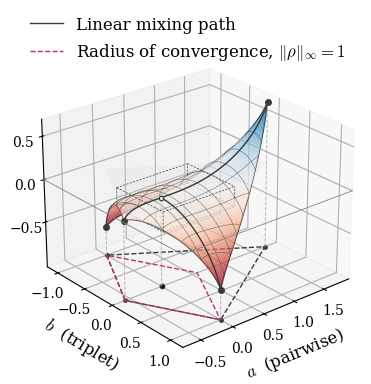

In [40]:
# ---------- panel b: the whole slice
plt.rcParams.update({"font.family": "serif", "mathtext.fontset": "cm", "font.size": 9, "axes.labelcolor": "black"})

amin, amax, bmin, bmax = -1 / SQ3, SQ3, -1.0, 1.0
u, v = np.meshgrid(np.linspace(0, 1, 90), np.linspace(0, 1, 90))
Fk, Gm, Ck, Gp = KITE                 # bilinear map of the unit square onto the kite
A = (1 - u) * (1 - v) * Fk[0] + u * (1 - v) * Gm[0] + u * v * Ck[0] + (1 - u) * v * Gp[0]
Bk = (1 - u) * (1 - v) * Fk[1] + u * (1 - v) * Gm[1] + u * v * Ck[1] + (1 - u) * v * Gp[1]
P = np.stack([sl.P(x, y) for x, y in zip(A.ravel(), Bk.ravel())])
assert P.min() > -1e-12, "region must lie inside the simplex"
Z = np.array([sl.omega(p) for p in P]).reshape(A.shape)

def b_limit(x):                       # half-width of the kite at a = x
    return np.maximum(np.minimum(1 + SQ3 * x, 1 - x / SQ3), 0.0)

fig = plt.figure(figsize=(5.2, 4.4))
ax = fig.add_subplot(111, projection="3d", computed_zorder=False)
norm = TwoSlopeNorm(vmin=Z.min(), vcenter=0.0, vmax=Z.max())
cmap = plt.get_cmap("RdBu")
zfloor = Z.min() - 0.25 * (Z.max() - Z.min())

ax.plot_surface(A, Bk, Z, facecolors=cmap(norm(Z)), rstride=1, cstride=1,
                linewidth=0, antialiased=True, alpha=0.8, shade=False, zorder=1)
# reference plane phi = 0 (the value of every measure at U)
ax.plot_surface(A, Bk, np.zeros_like(Z), color="#d9d9d6", alpha=0.18, linewidth=0,
                antialiased=True, shade=False, zorder=2)

# iso-parameter lines: curvature along b (parabolas), cubic tilt along a (S-curves)
nb, na = 9, 9
for y0 in np.linspace(bmin, bmax, nb + 2)[1:-1]:          # lines of constant b
    xs = np.linspace(amin, amax, 150)
    xs = xs[b_limit(xs) >= abs(y0) - 1e-12]
    if len(xs) > 1:
        ax.plot(xs, 0 * xs + y0, [sl.omega(sl.P(x, y0)) for x in xs], color=SL_INK, lw=0.5, alpha=0.55, zorder=3)
for x0 in np.linspace(amin, amax, na + 2)[1:-1]:          # lines of constant a
    h = min(b_limit(x0), max(abs(bmin), abs(bmax)))
    ys = np.linspace(max(-h, bmin), min(h, bmax), 120)
    ax.plot(0 * ys + x0, ys, [sl.omega(sl.P(x0, y)) for y in ys], color=SL_INK, lw=0.5, alpha=0.55, zorder=3)

# outline of the kite and its vertices on the floor
k = np.vstack([KITE, KITE[:1]])
ax.plot(k[:, 0], k[:, 1], zfloor, "--", color=SL_INK, lw=1.0, zorder=0.5)
for x, y in KITE:
    ax.scatter([x], [y], [zfloor], color=SL_INK, s=6, depthshade=False, zorder=0.)

# dashed box: the region of the zoom (panel c); vertical edges are split where they cross the surface
corners = np.array([(x, y, z) for x in (a[0], a[-1]) for y in (b[0], b[-1]) for z in (z0, z1)])
for i in range(8):
    for j in range(i + 1, 8):
        if np.sum(corners[i] != corners[j]) == 1:          # edge: differ in exactly one coordinate
            p, q = corners[i], corners[j]
            if q[2] > 0 and p[2] > 0:
                ax.plot([p[0], q[0]], [p[1], q[1]], [p[2], q[2]], color=SL_INK, lw=0.5, ls=(0, (3, 2)), zorder=20)
            elif q[2] > 0 and p[2] < 0:
                ax.plot([p[0], q[0]], [p[1], q[1]], [p[2], sl.omega(sl.P(p[0], p[1]))], color=SL_INK, lw=0.5,
                        ls=(0, (3, 2)), zorder=0)
                ax.plot([p[0], q[0]], [p[1], q[1]], [sl.omega(sl.P(q[0], q[1])), q[2]], color=SL_INK, lw=0.5,
                        ls=(0, (3, 2)), zorder=20)
            else:
                ax.plot([p[0], q[0]], [p[1], q[1]], [p[2], q[2]], color=SL_INK, lw=0.5, ls=(0, (3, 2)), zorder=0)

# border of the surface: phi along the edge of the kite
edge = np.vstack([np.linspace(p, q, 120, endpoint=False) for p, q in zip(KITE, np.roll(KITE, -1, axis=0))])
edge = np.vstack([edge, edge[:1]])
ax.plot(edge[:, 0], edge[:, 1], [sl.omega(sl.P(x, y)) for x, y in edge], color=SL_INK, lw=0.9, zorder=0)

# radius of convergence ||rho||_inf = 1, on the floor
rh = np.vstack([np.linspace(p, q, 200, endpoint=False) for p, q in zip(RHOMBUS, np.roll(RHOMBUS, -1, axis=0))])
rh = np.vstack([rh, rh[:1]])
ax.plot(rh[:, 0], rh[:, 1], np.full(len(rh), zfloor), "--", color=C_RADIUS, lw=1., zorder=9)

# linear mixing paths: the ridge b = 0 (towards COPY for a > 0, frustrated side for a < 0) and towards GXOR
ridge_a = np.linspace(-1 / SQ3 + 1e-9, amax, 220)
ridge = np.array([sl.omega(sl.P(x, 0.0)) for x in ridge_a])
rt = np.array([sl.terms(sl.P(x, 0.0)) for x in ridge_a])
assert np.allclose(rt[:, 0], 0, atol=1e-12)                                  # lambda_2 = 0
assert np.allclose(rt[:, 1], ridge_a ** 3 / (3 * np.sqrt(3)), rtol=1e-8, atol=1e-12)   # Eq. slice-cubic
gb = np.linspace(0, bmax, 120)
gx = np.array([sl.omega(sl.P(0.0, y)) for y in gb])
gt = np.array([sl.terms(sl.P(0.0, y)) for y in gb])
assert np.allclose(gt[:, 0], -gb ** 2 / 2) and np.allclose(gt[:, 1], 0, atol=1e-12)
zr = lambda z: np.where((z >= zfloor) & (z <= Z.max()), z, np.nan)
LS_EXACT = dict(ls="-", lw=1.0)
ax.plot(ridge_a, 0 * ridge_a, zr(ridge), color=SL_INK, zorder=10, **LS_EXACT)
ax.plot(0 * gb, gb, zr(gx), color=SL_INK, zorder=10, **LS_EXACT)

# the four vertices on the surface, with drop lines to the floor
ends = ((SQ3, 0, sl.omega(sl.P(SQ3, 0))), (-1 / SQ3, 0, sl.omega(sl.P(-1 / SQ3, 0))),
        (0, 1, sl.omega(sl.P(0, 1))), (0, -1, sl.omega(sl.P(0, -1))))
for (x, y, z) in ends:
    ax.scatter([x], [y], [z], color=SL_INK, s=16, zorder=12, depthshade=False)
    ax.plot([x, x], [y, y], [zfloor, z], linestyle="dashed", color="#b5b5b0", lw=0.7, zorder=0.5)

# U, on the surface and on the floor
ax.scatter([0], [0], [0], color="white", edgecolor=SL_INK, s=10, zorder=13)
ax.plot([0, 0], [0, 0], [zfloor, 0], linestyle="dashed", color="#b5b5b0", lw=0.7, zorder=0.5)
ax.scatter(0, 0, zfloor, color="black", edgecolor=SL_INK, s=10, zorder=0, depthshade=False)

# frame of the plane phi = 0 (back edges drawn lighter than the front ones)
borExt = 0.2
ax.plot([amin - borExt, amax + borExt, amax + borExt], [bmin - borExt, bmin - borExt, bmax + borExt], [0] * 3,
        color="#b5b5b0", lw=0.6, alpha=0.8)
ax.plot([amax + borExt, amin - borExt, amin - borExt], [bmax + borExt, bmax + borExt, bmin - borExt], [0] * 3,
        color="#83837b", lw=0.6, alpha=1, zorder=20)

handles = [Line2D([], [], color=SL_INK, **LS_EXACT, label="Linear mixing path"),
           Line2D([], [], linestyle="--", color=C_RADIUS, lw=1., label=r"Radius of convergence, $\|\rho\|_\infty=1$")]
ax.set_xlim(amin - 0.2, amax + 0.2); ax.set_ylim(bmax + 0.2, bmin - 0.2); ax.set_zlim(zfloor, Z.max())
ax.set_xlabel(r"$a$  (pairwise)", labelpad=2, fontsize=fs)
ax.set_ylabel(r"$b$  (triplet)", labelpad=2, fontsize=fs)
ax.set_zticks([-0.5, 0, 0.5]); ax.set_xticks(np.arange(-0.5, 2, 0.5)); ax.set_yticks(np.arange(-1, 1.5, 0.5))
ax.tick_params(labelsize=fs - 2, pad=0., colors="black")
ax.view_init(elev=25, azim=-130)
ax.legend(handles=handles, loc=(0., 0.9), frameon=False, fontsize=fs)
save(fig, "Figure_3_b", dpi=600)
plt.show()

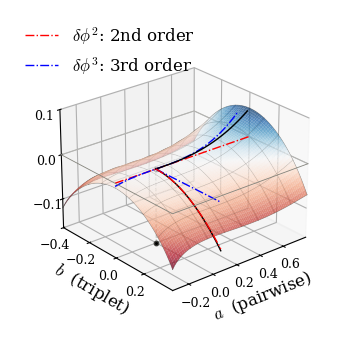

q = 2: delta^2 = 0 and delta^3 = a^3/(3 sqrt3) along the pairwise axis; delta^2 = -b^2/2, delta^3 = 0 towards XOR


In [41]:
# ---------- panel c: zoom around U, with the second and third variations along the two mixing paths
C_COPY, C_GXOR = "#008300", "#eda100"
tmax = 0.45
A, Bz, Z = A_z, B_z, Z_z                       # the zoom region defined above

fig = plt.figure(figsize=(5.2, 4.4))
ax = fig.add_subplot(111, projection="3d")
norm = TwoSlopeNorm(vmin=Z.min(), vcenter=0.0, vmax=Z.max())
cmap = plt.get_cmap("RdBu")
zfloor = Z.min() - 0.25 * (Z.max() - Z.min())

ax.plot_surface(A, Bz, Z, facecolors=cmap(norm(Z)), rstride=1, cstride=1,
                linewidth=0, antialiased=True, alpha=0.75, shade=False)
# iso-parameter lines
for i in range(0, len(b), 8):
    ax.plot(A[i], Bz[i], Z[i], color=SL_INK, lw=0.5, alpha=0.6)
for j in range(0, len(a), 10):
    ax.plot(A[:, j], Bz[:, j], Z[:, j], color=SL_INK, lw=0.5, alpha=0.6)

# mixing paths towards COPY and towards GXOR, t in [0, tmax]
t = np.linspace(0, tmax, 80)
for a1, b1 in ((ac, bc), (ag, bg)):
    pa, pb = t * a1, t * b1
    pz = np.array([sl.omega(sl.P(x, y)) for x, y in zip(pa, pb)])
    ax.plot(pa, pb, pz, color="k", lw=1, zorder=10)

# frame of the plane phi = 0 (back edges drawn lighter than the front ones)
ax.plot([a.min(), a.max(), a.max()], [b.min(), b.min(), b.max()], [0] * 3, color="#b5b5b0", lw=0.6, alpha=0.8)
ax.plot([a.max(), a.min(), a.min()], [b.max(), b.max(), b.min()], [0] * 3, color="#83837b", lw=0.6, alpha=1, zorder=20)

# the ridge b = 0: its second variation is flat (lambda_2 = 0), so U is an inflection point
ridge_a = np.linspace(a.min(), a.max(), 200)
ax.plot(ridge_a, 0 * ridge_a, 0 * ridge_a, "-.", color="red", lw=1.0, zorder=9, label=r"$\delta\phi^{2}$: 2nd order")
# third variation: pairwise directions closing into triangles, weighted by lambda_3
cubic = ridge_a ** 3 / (3 * np.sqrt(3))
d3 = np.array([sl.terms(sl.P(x, 0.0))[1] for x in ridge_a[::20]])
assert np.allclose(d3, cubic[::20], rtol=1e-8, atol=1e-12)
ax.plot(ridge_a, 0 * ridge_a, np.where(cubic <= Z.max(), cubic, np.nan), color="blue", lw=1, ls="-.", zorder=9,
        label=r"$\delta\phi^{3}$: 3rd order")

# GXOR path: second variation -b^2/2 (lambda_3 = -1); the third vanishes for q = 2
gb = t * bg
o2 = np.array([sl.terms(sl.P(0.0, y))[0] for y in gb])
o3 = np.array([sum(sl.terms(sl.P(0.0, y))) for y in gb])
assert np.allclose(o2, -gb ** 2 / 2) and np.allclose(o3, o2)
ax.plot(0 * gb, gb, np.zeros(len(o2)), "-.", color="blue", lw=1., zorder=12)
ax.plot(0 * gb, gb, o2, "-.", color="red", lw=1., zorder=13)

# U, on the surface and on the floor
ax.scatter([0], [0], [0], color="white", edgecolor=SL_INK, s=10, zorder=20)
ax.plot([0, 0], [0, 0], [zfloor, 0], linestyle="dashed", color="#b5b5b0", lw=0.7, zorder=0.5)
ax.scatter(0, 0, zfloor, color="black", edgecolor=SL_INK, s=10, zorder=0, depthshade=False)

ax.set_xlim(a.min(), a.max()); ax.set_ylim(b.max(), b.min()); ax.set_zlim(zfloor, Z.max())
ax.set_xlabel(r"$a$  (pairwise)", labelpad=2, fontsize=fs)
ax.set_ylabel(r"$b$  (triplet)", labelpad=2, fontsize=fs)
ax.set_zticks([-0.1, 0, 0.1]); ax.set_xticks(np.arange(-0.2, 0.7, 0.2)); ax.set_yticks(np.arange(-0.4, 0.4, 0.2))
ax.tick_params(labelsize=fs - 3, pad=0., colors="black")
ax.view_init(elev=25, azim=-130)
ax.set_box_aspect(aspect=None, zoom=0.8)
ax.legend(loc="upper left", frameon=False, fontsize=fs)
save(fig, "Figure_3_c", dpi=600)
plt.show()
print("q = 2: delta^2 = 0 and delta^3 = a^3/(3 sqrt3) along the pairwise axis; delta^2 = -b^2/2, delta^3 = 0 towards XOR")
plt.rcParams.update({"font.size": 9})

## 4. Paths from independence: mixtures and maximum entropy (Fig. 5)

O-information along the linear mixture $\mathbb P_\varepsilon=(1-\varepsilon)\mathbb U+\varepsilon\mathbb P_{\rm target}$ and along the maximum-entropy distribution with the same pairwise marginals, for three targets: independent variables biased by a common field (the MaxEnt path is an Ising model with a uniform field and coupling), two independent copies, and COPY (the MaxEnt path is the ferromagnetic Potts model). The functions assert Eq. (mixing-omega) for the second variation of each mixture, and, for the two independent copies, $\delta^2\Omega=-\varepsilon^2$, $\delta^2\Omega+\delta^3\Omega=-\varepsilon^2+2\varepsilon^3$ and $\Omega=0$ along the product of the two pairs.

field p=0.05 N= 4: mixture min -0.0080 ln 2 at eps=0.155, positive from eps=0.285; MaxEnt min +3.1e-09
field p=0.05 N= 6: mixture min -0.0182 ln 2 at eps=0.088, positive from eps=0.181; MaxEnt min +1.5e-08
field p=0.05 N= 9: mixture min -0.0209 ln 2 at eps=0.040, positive from eps=0.091; MaxEnt min +6.4e-08
field p=0.05 N=12: mixture min -0.0165 ln 2 at eps=0.020, positive from eps=0.048; MaxEnt min +1.7e-07
two copies: mixture minimum -0.1883 ln 2 at eps = 0.73; negative for all 0 < eps < 1: True
q=2 N= 4: mixture min -0.0044 ln q at eps=0.109; MaxEnt min +7.2e-13, monotone True
q=2 N= 6: mixture min -0.0452 ln q at eps=0.118; MaxEnt min +3.6e-12, monotone True
q=2 N= 9: mixture min -0.0758 ln q at eps=0.064; MaxEnt min +1.5e-11, monotone True
q=2 N=12: mixture min -0.0510 ln q at eps=0.027; MaxEnt min +4.0e-11, monotone True
q=3 N= 3: mixture min -0.0047 ln q at eps=0.147; MaxEnt min +6.8e-14, monotone True
q=3 N= 4: mixture min -0.0282 ln q at eps=0.147; MaxEnt min +2.7e-13, monoton

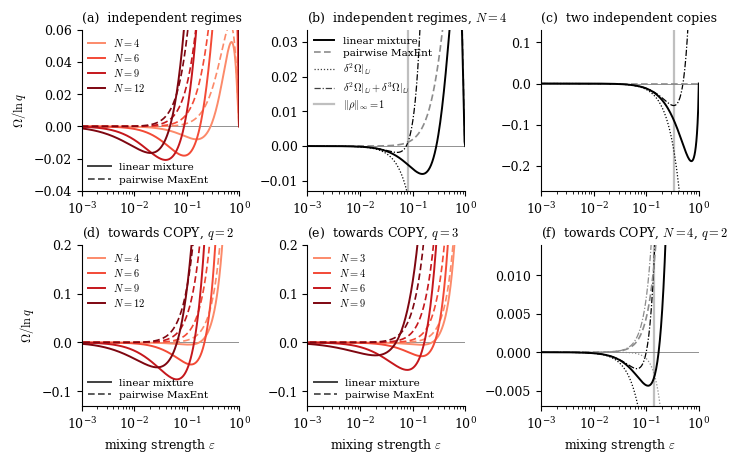

In [42]:
P_FIELD, FIELD_NS = 0.05, (4, 6, 9, 12)
PANELS = [(2, (4, 6, 9, 12)), (3, (3, 4, 6, 9))]
EPS_MIN, YLIM, fs = 1e-3, (-0.1, 0.2), 9
R_, B_ = "black", "0.55"                     # single-system panels: mixture black, MaxEnt grey
MIX, ME = "-", (0, (4, 2))                     # linestyles: linear mixture, pairwise MaxEnt (all panels)
DOT, DASHDOT = (0, (1, 1.5)), (0, (5, 1.5, 1, 1.5))
RAD_KW = dict(color="0.75", lw=1.6, ls="-", zorder=0)      # radius of convergence of the expansion along the mixture

def style(ax, ylim=YLIM):
    ax.axhline(0, color="gray", lw=0.6, zorder=1)
    ax.set_xscale("log"); ax.set_xlim(EPS_MIN, 1); ax.set_ylim(*ylim)
    ax.set_xlabel(r"mixing strength $\varepsilon$", fontsize=fs)
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)

def family(ax, curves, Ns, ylim):
    """Several N: one color per N; solid = mixture, dashed = pairwise MaxEnt."""
    cols = plt.cm.Reds(np.linspace(0.40, 0.95, len(Ns)))
    style(ax, ylim)
    for (mix, me), c in zip(curves, cols):
        ax.plot(me["eps"], me["y"], color=c, lw=1.2, ls=ME); ax.plot(mix["eps"], mix["y"], color=c, lw=1.4, ls=MIX)
    leg = ax.legend([Line2D([], [], color=c, lw=1.4) for c in cols], [rf"$N={N}$" for N in Ns], frameon=False,
                    fontsize=fs - 1.5, loc="upper left", handlelength=1.6, labelspacing=0.3, borderaxespad=0.2)
    ax.add_artist(leg)
    ax.legend([Line2D([], [], color="0.25", lw=1.4, ls=MIX), Line2D([], [], color="0.25", lw=1.2, ls=ME)],
              ["linear mixture", "pairwise MaxEnt"], frameon=False, fontsize=fs - 1.5, loc="lower left",
              handlelength=2.2, labelspacing=0.3, borderaxespad=0.2)

def variations(ax, mix, me, me_variations=True):
    """One system: exact paths (solid/dashed), second (dotted) and second+third (dash-dot) variations, radius."""
    ax.axvline(mix["radius"], **RAD_KW)
    ax.plot(mix["eps"], mix["o2"], color=R_, lw=0.9, ls=DOT); ax.plot(mix["eps"], mix["o23"], color=R_, lw=0.9, ls=DASHDOT)
    if me_variations:
        ax.plot(me["eps"], me["o2"], color=B_, lw=0.9, ls=DOT); ax.plot(me["eps"], me["o23"], color=B_, lw=0.9, ls=DASHDOT)
    ax.plot(me["eps"], me["y"], color=B_, lw=1.2, ls=ME); ax.plot(mix["eps"], mix["y"], color=R_, lw=1.4, ls=MIX)

fig, axes2 = plt.subplots(2, 3, figsize=(18 * cm, 11.5 * cm), layout="constrained")
axes = axes2.ravel()

# (a) independent regimes: uniform and a common field (each variable active with probability P_FIELD)
ax = axes[0]
curves = [paths.field_paths(N, P_FIELD) for N in FIELD_NS]
family(ax, curves, FIELD_NS, (-0.04, 0.06))
ax.set_title(r"(a)  independent regimes", fontsize=fs, loc="left")
for N, (mix, me) in zip(FIELD_NS, curves):
    i = mix["y"].argmin(); pos = mix["eps"][mix["y"] > 0]
    print(f"field p={P_FIELD} N={N:2d}: mixture min {mix['y'][i]:+.4f} ln 2 at eps={mix['eps'][i]:.3f}, "
          f"positive from eps={pos.min():.3f}; MaxEnt min {me['y'].min():+.1e}")

# (b) the same, N = 4, with the variations of the mixture; this panel carries the legend of (b), (c), (f)
ax = axes[1]; style(ax); mix, me = paths.field_paths(4, P_FIELD)
variations(ax, mix, me, me_variations=False)
lo = 1.6 * mix["y"].min(); ax.set_ylim(lo, -2.6 * lo)
ax.set_title(r"(b)  independent regimes, $N=4$", fontsize=fs, loc="left")
ax.legend([Line2D([], [], color=R_, lw=1.4, ls=MIX), Line2D([], [], color=B_, lw=1.2, ls=ME),
           Line2D([], [], color="0.25", lw=0.9, ls=DOT), Line2D([], [], color="0.25", lw=0.9, ls=DASHDOT),
           Line2D([], [], **RAD_KW)],
          ["linear mixture", "pairwise MaxEnt", r"$\delta^{2}\Omega|_{\mathbb{U}}$",
           r"$\delta^{2}\Omega|_{\mathbb{U}}+\delta^{3}\Omega|_{\mathbb{U}}$", r"$\|\rho\|_\infty=1$"],
          frameon=False, fontsize=fs - 1.5, loc="upper left", handlelength=2.0, labelspacing=0.3, borderaxespad=0.2)

# (c) two independent copies (MaxEnt: the product of two independent pairs, Omega = 0)
ax = axes[2]; style(ax); mix, me = paths.two_copies_paths()
variations(ax, mix, me, me_variations=False)
ax.set_ylim(-0.26, 0.13)
ax.set_title(r"(c)  two independent copies", fontsize=fs, loc="left")
i = mix["y"].argmin()
print(f"two copies: mixture minimum {mix['y'][i]:+.4f} ln 2 at eps = {mix['eps'][i]:.2f}; negative for all 0 < eps < 1: {bool(np.all(mix['y'][:-1] < 0))}")

# (d, e) towards COPY, several N
for ax, (q, Ns), tag in zip(axes[3:5], PANELS, "de"):
    curves = [paths.copy_paths(N, q) for N in Ns]
    family(ax, curves, Ns, (-0.13, 0.2))
    ax.set_title(rf"({tag})  towards COPY, $q={q}$", fontsize=fs, loc="left")
    for N, (mix, me) in zip(Ns, curves):
        print(f"q={q} N={N:2d}: mixture min {mix['y'].min():+.4f} ln q at eps={mix['eps'][mix['y'].argmin()]:.3f}; "
              f"MaxEnt min {me['y'].min():+.1e}, monotone {bool(np.all(np.diff(me['y']) > -1e-11))}")

# (f) towards COPY, N = 4, q = 2, with the variations of both paths
ax = axes[5]; style(ax); mix, me = paths.copy_paths(4, 2)
variations(ax, mix, me)
k = me["eps"] < 0.02
print("MaxEnt, N=4, q=2: (delta^2 + delta^3) / Eq. (maxent-omega) at small eps:", np.round((me["o23"][k] / me["lead"][k])[[0, -1]], 3))
lo = 1.6 * min(mix["y"].min(), -1e-3); ax.set_ylim(lo, -2 * lo)
ax.set_title(r"(f)  towards COPY, $N=4$, $q=2$", fontsize=fs, loc="left")

for ax in axes[:3]: ax.set_xlabel("")
for ax in (axes[0], axes[3]): ax.set_ylabel(r"$\Omega/\ln q$")
save(fig, "Figure_5_Mixing_vs_maxent", dpi=600)
plt.show()


## 5. Sampling bias of discrete measures (Fig. 5a,b, SI Fig. bias, SI Tables S-beta and S-bias)

Plug-in estimates on $T$ independent samples from the uniform distribution of $N=6$ variables. The exact mean is Eq. (bias-exact), $\mathbb E[\hat\phi]=\sum_m\lambda_m\binom Nm\beta_m(T)$; its large-sample form is Eq. (bias). We first check that the two expressions of the exact mean (through the $c_k$ and through the order weights) agree.

In [43]:
for q in (2, 3, 4):
    for name in ("TC", "DTC", "Sigma", "TSE", "Omega", "OmegaStar", "coI"):
        c = M.coeffs(name, 6)
        for T in (q ** 3, q ** 6):
            assert np.isclose(B.exact_bias(c, 6, q, T), B.exact_bias_lambda(c, 6, q, T), rtol=1e-9, atol=1e-12)
print("exact mean: c_k form (SI Eq. S-mean-uniform) = order-weight form (main Eq. bias-exact)")

exact mean: c_k form (SI Eq. S-mean-uniform) = order-weight form (main Eq. bias-exact)


In [44]:
def run_violins(names, N, qs, ratios, R, seed):
    """Simulations behind the violin figures, in the order of the original runs (one random stream)."""
    rng = np.random.default_rng(seed)
    return {(q, ratio): B.simulate_uniform(N, q, int(round(ratio * q ** N)), R, names, rng)
            for q in qs for ratio in ratios}

def violin_figure(sims, names, N, qs, ratios, name, width=17.0, legend_ax=0, legend_loc="best"):
    cols = plt.cm.Blues(np.linspace(0.45, 0.9, len(ratios)))
    fig, axes = plt.subplots(1, len(qs), figsize=(width * cm, 8.5 * cm), constrained_layout=True, squeeze=False)
    for ax, q in zip(axes[0], qs):
        ax.axhline(0, color="gray", lw=0.8, zorder=1); w = 0.8 / len(ratios)
        for j, ratio in enumerate(ratios):
            T = int(round(ratio * q ** N)); s_ = sims[(q, ratio)]
            for i, n in enumerate(names):
                c = M.coeffs(n, N); s = M.hallmark_scale(c, q); x = i + (j - (len(ratios) - 1) / 2) * w
                v = ax.violinplot(s_[n] / s, positions=[x], widths=w * 0.9, showextrema=False)
                for b in v["bodies"]: b.set_facecolor(cols[j]); b.set_edgecolor("white"); b.set_linewidth(0.5); b.set_alpha(1)
                ax.plot([x - w * 0.4, x + w * 0.4], [B.exact_bias(c, N, q, T) / s] * 2, color=INK, lw=1.2, zorder=4)
                ax.plot([x - w * 0.4, x + w * 0.4], [B.leading_bias(c, N, q, T) / s] * 2, color=FIRST, lw=1.2, ls=(0, (2, 1.2)), zorder=5)
        ax.set_xticks(range(len(names))); ax.set_xticklabels([M.LABEL[n] for n in names], fontsize=11)
        ax.set_title(rf"$q={q}$  ({q**N} states)", loc="left", fontsize=11)
        ax.grid(axis="y", color=GRID, lw=0.7); ax.set_axisbelow(True)
        for sp in ("top", "right"): ax.spines[sp].set_visible(False)
    axes[0][0].set_ylabel("Estimate on independent data\n(relative to hallmark value)", fontsize=11)
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in cols] + [Line2D([], [], color=INK, lw=1.2), Line2D([], [], color=FIRST, lw=1.2, ls=(0, (2, 1.2)))]
    axes[0][legend_ax].legend(handles, [rf"$T/q^N={r:g}$" for r in ratios] + ["exact mean", r"first term, $O(1/T)$"],
                              frameon=False, fontsize=9, loc=legend_loc)
    save(fig, name, dpi=250)
    plt.show()

MAIN = dict(names=["Omega", "Sigma", "coI"], N=6, qs=(2, 3), ratios=(1, 5, 10))
SI = dict(names=["TC", "DTC", "Sigma", "TSE", "Omega", "OmegaStar", "coI"], N=6, qs=(2, 3, 4), ratios=(1, 5, 10))
sims_main = cached("bias_violins_main", lambda: run_violins(**MAIN, R=1000, seed=0))   # Fig. 5a,b, drawn in Sec. 6

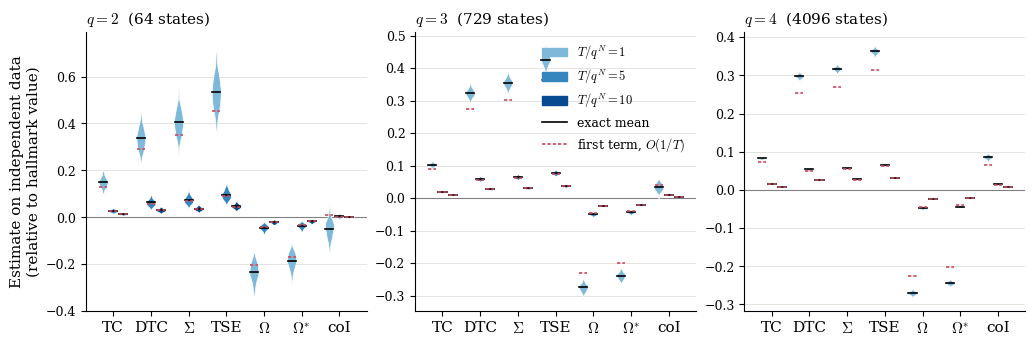

In [45]:
sims_SI = cached("bias_violins_SI", lambda: run_violins(**SI, R=600, seed=0))
violin_figure(sims_SI, **SI, name="SI_Figure_2_More_bias_measure", width=26.0, legend_ax=1, legend_loc="upper right")

In [46]:
# SI Table S-bias: q = 2, 3 from the main-text run (1000 data sets), q = 4 from the SI run (600 data sets)
rows = []
for q in (2, 3, 4):
    src = sims_main if q in (2, 3) else sims_SI
    for ratio in (1, 10):
        T = ratio * q ** 6
        for n in ("Omega", "Sigma", "coI"):
            c = M.coeffs(n, 6); s = src[(q, ratio)][n]
            rows.append(dict(q=q, T=T, measure=n, simulated_mean=s.mean(), exact=B.exact_bias(c, 6, q, T),
                             first_term=B.leading_bias(c, 6, q, T), sd=s.std()))
tabS_bias = pd.DataFrame(rows)
save_table(tabS_bias, "tab_S-bias", floatfmt="%.4f")
print(tabS_bias.round(4).to_string(index=False))

 q     T measure  simulated_mean   exact  first_term     sd
 2    64   Omega         -0.6509 -0.6536     -0.5625 0.1081
 2    64   Sigma          1.6905  1.6936      1.4531 0.2128
 2    64     coI         -0.0349 -0.0341      0.0078 0.0284
 2   640   Omega         -0.0584 -0.0587     -0.0562 0.0148
 2   640   Sigma          0.1491  0.1496      0.1453 0.0305
 2   640     coI          0.0010  0.0010      0.0008 0.0014
 3   729   Omega         -1.2077 -1.2093     -1.0096 0.0450
 3   729   Sigma          2.3382  2.3386      1.9918 0.0811
 3   729     coI          0.0375  0.0385      0.0439 0.0130
 3  7290   Omega         -0.1040 -0.1041     -0.1010 0.0064
 3  7290   Sigma          0.2039  0.2042      0.1992 0.0114
 3  7290     coI          0.0049  0.0049      0.0044 0.0008
 4  4096   Omega         -1.4968 -1.4978     -1.2524 0.0245
 4  4096   Sigma          2.6376  2.6400      2.2478 0.0422
 4  4096     coI          0.1190  0.1189      0.0890 0.0060
 4 40960   Omega         -0.1288 -0.1287

In [47]:
# Mean / standard deviation of the estimates (main text: 'about four standard deviations below zero for
# q = 2 and sixteen for q = 3'), from the simulations and from SI Eq. S-ratio
for q in (2, 3, 4):
    D = {m: comb(6, m) * (q - 1) ** m for m in range(2, 7)}
    for n in ("Omega", "Sigma"):
        lam = [float(x) for x in M.order_weights(M.c_measure(n, 6))]
        pred = sum(lam[m - 1] * D[m] for m in D) / np.sqrt(2 * sum(lam[m - 1] ** 2 * D[m] for m in D))
        src = sims_main if q in (2, 3) else sims_SI
        sim = [src[(q, r)][n].mean() / src[(q, r)][n].std() for r in (1, 5, 10)]
        print(f"q={q} {n:5s}: Eq. S-ratio {pred:+6.1f};  simulated at T/q^N = 1, 5, 10: " + ", ".join(f"{x:+6.1f}" for x in sim))

# 'With one sample per state, the O-information of an independent system is about a quarter of its value at
# GXOR, and the estimate of Sigma more than a third of its value at COPY'
for q in (2, 3, 4):
    om = B.exact_bias(M.coeffs("Omega", 6), 6, q, q ** 6) / (4 * log(q))
    sg = B.exact_bias(M.coeffs("Sigma", 6), 6, q, q ** 6) / (6 * log(q))
    print(f"q={q}, T=q^N: E[Omega_hat]/|Omega(GXOR)| = {om:+.3f},  E[Sigma_hat]/Sigma(COPY) = {sg:+.3f}")

q=2 Omega: Eq. S-ratio   -4.2;  simulated at T/q^N = 1, 5, 10:   -6.0,   -3.9,   -3.9
q=2 Sigma: Eq. S-ratio   +5.1;  simulated at T/q^N = 1, 5, 10:   +7.9,   +4.9,   +4.9
q=3 Omega: Eq. S-ratio  -16.7;  simulated at T/q^N = 1, 5, 10:  -26.8,  -16.3,  -16.4
q=3 Sigma: Eq. S-ratio  +18.3;  simulated at T/q^N = 1, 5, 10:  +28.8,  +18.0,  +17.8
q=4 Omega: Eq. S-ratio  -41.8;  simulated at T/q^N = 1, 5, 10:  -61.1,  -41.7,  -43.5
q=4 Sigma: Eq. S-ratio  +44.0;  simulated at T/q^N = 1, 5, 10:  +62.6,  +44.0,  +45.5
q=2, T=q^N: E[Omega_hat]/|Omega(GXOR)| = -0.236,  E[Sigma_hat]/Sigma(COPY) = +0.407
q=3, T=q^N: E[Omega_hat]/|Omega(GXOR)| = -0.275,  E[Sigma_hat]/Sigma(COPY) = +0.355
q=4, T=q^N: E[Omega_hat]/|Omega(GXOR)| = -0.270,  E[Sigma_hat]/Sigma(COPY) = +0.317


In [48]:
# SI Table S-beta: exact beta_m(T) divided by its leading value (q-1)^m / 2T
rows = []
for q, mmax in ((2, 6), (3, 6), (4, 5)):
    for m in range(2, mmax + 1):
        row = dict(q=q, m=m)
        for lab, f in (("T=q^m/2", 0.5), ("T=q^m", 1), ("T=2q^m", 2), ("T=5q^m", 5)):
            T = int(round(f * q ** m))      # q^m/2 rounded to the nearest integer (13.5 -> 14)
            row[lab] = B.beta_m(m, q, T) / ((q - 1) ** m / (2 * T))
        rows.append(row)
tabS_beta = pd.DataFrame(rows)
save_table(tabS_beta, "tab_S-beta", floatfmt="%+.2f")
print(tabS_beta.round(2).to_string(index=False))

 q  m  T=q^m/2  T=q^m  T=2q^m  T=5q^m
 2  2     0.69   1.32    1.37    1.11
 2  3    -0.08   1.01    1.55    1.18
 2  4    -0.99   0.30    1.76    1.31
 2  5    -1.99  -1.22    1.97    1.53
 2  6    -2.46  -4.37    2.06    1.91
 3  2     0.80   1.26    1.27    1.08
 3  3     0.61   1.24    1.37    1.12
 3  4     0.12   1.19    1.50    1.17
 3  5    -0.52   1.09    1.68    1.23
 3  6    -1.61   0.88    1.93    1.32
 4  2     0.95   1.23    1.23    1.07
 4  3     0.80   1.25    1.29    1.10
 4  4     0.61   1.28    1.37    1.12
 4  5     0.36   1.31    1.47    1.16


### Fewer samples than states (SI Fig. saturation)

Exact mean of the plug-in O- and S-information down to a few samples. For $T\ll q^{N-1}$ the saturation formula (SI, Eq. S-omega-sat) applies, and the bias of $\Omega$ becomes positive below about $q^{N/2}$ samples.

q  N | crossing T* | q^(N/2) | min E[Omega]/|Omega(GXOR)| at T/q^N | max E[Sigma]/(N ln q)
2  6 |    10 |     8.0 | -0.267 at 0.61 | 0.799
        T=  4: exact +0.7297, saturation formula +0.7339
2 10 |    34 |    32.0 | -0.437 at 0.35 | 0.948
        T=  4: exact +2.6627, saturation formula +2.6628
        T= 16: exact +1.1839, saturation formula +1.1849
        T= 64: exact -0.9700, saturation formula -0.9533
2 14 |   131 |   128.0 | -0.543 at 0.23 | 0.987
        T=  4: exact +4.8048, saturation formula +4.8048
        T= 16: exact +3.7164, saturation formula +3.7165
        T= 64: exact +1.3186, saturation formula +1.3187
3  6 |    30 |    27.0 | -0.421 at 0.31 | 0.922
        T=  4: exact +1.9638, saturation formula +1.9638
        T= 16: exact +0.8491, saturation formula +0.8519
3  8 |    84 |    81.0 | -0.519 at 0.23 | 0.974
        T=  4: exact +3.4951, saturation formula +3.4951
        T= 16: exact +2.7465, saturation formula +2.7465
        T= 64: exact +0.4637, saturation f

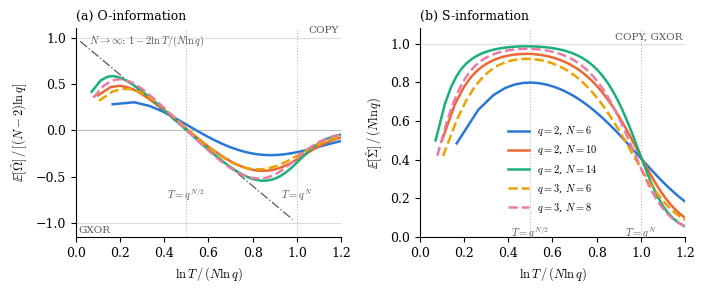

In [49]:
cases = [(2, 6), (2, 10), (2, 14), (3, 6), (3, 8)]
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]

def saturation_curves():
    out = {}
    for q, N in cases:
        Ts = np.unique(np.round(np.logspace(np.log10(2), np.log10(8 * q ** N), 70)).astype(int))
        out[(q, N)] = (Ts, np.array([B.omega_sigma_exact(N, q, T) for T in Ts]))
    return out
sat = cached("bias_saturation", saturation_curves)

print("q  N | crossing T* | q^(N/2) | min E[Omega]/|Omega(GXOR)| at T/q^N | max E[Sigma]/(N ln q)")
for q, N in cases:
    c = q ** (N / 2)
    Tint = np.arange(max(2, int(c / 4)), int(4 * c) + 1)
    vals = np.array([B.omega_sigma_exact(N, q, T)[0] for T in Tint])
    idx = np.where(np.diff(np.sign(vals)) != 0)[0]
    Ts, v = sat[(q, N)]; om, sg = v[:, 0], v[:, 1]; i = om.argmin()
    print(f"{q} {N:2d} | {Tint[idx[0] + 1]:5d} | {c:7.1f} | {om[i] / ((N - 2) * log(q)):+.3f} at {Ts[i] / q ** N:.2f} | {sg.max() / (N * log(q)):.3f}")
    for T in (4, 16, 64):
        if T < q ** (N - 1) / 4:
            print(f"        T={T:3d}: exact {B.omega_sigma_exact(N, q, T)[0]:+.4f}, saturation formula {B.omega_saturation(N, q, T):+.4f}")

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.0), sharex=True)
for (q, N), col in zip(cases, colors):
    Ts, v = sat[(q, N)]; x = np.log(Ts) / (N * log(q)); ls = "-" if q == 2 else "--"
    axes[0].plot(x, v[:, 0] / ((N - 2) * log(q)), ls, color=col, lw=1.8, label=f"$q={q}$, $N={N}$")
    axes[1].plot(x, v[:, 1] / (N * log(q)), ls, color=col, lw=1.8, label=f"$q={q}$, $N={N}$")
xs = np.linspace(0.02, 0.98, 50)
axes[0].plot(xs, 1 - 2 * xs, color="#666666", lw=1.0, ls="-.", zorder=1)
axes[0].text(0.06, 0.93, r"$N\to\infty$: $1-2\ln T/(N\ln q)$", fontsize=7.5, color="#555555")
for ax in axes:
    ax.axhline(0, color="#bbbbbb", lw=0.8, zorder=0)
    for xv in (0.5, 1): ax.axvline(xv, color="#bbbbbb", lw=0.8, ls=":", zorder=0)
    ax.set_xlabel(r"$\ln T\,/\,(N\ln q)$"); ax.set_xlim(0, 1.2)
axes[0].set_ylim(-1.15, 1.1); axes[1].set_ylim(0, 1.08)
for y in (1, -1): axes[0].axhline(y, color="#dddddd", lw=0.8, zorder=0)
axes[0].text(1.19, 1.03, "COPY", ha="right", va="bottom", fontsize=7.5, color="#555555")
axes[0].text(0.01, -1.03, "GXOR", ha="left", va="top", fontsize=7.5, color="#555555")
axes[1].axhline(1, color="#dddddd", lw=0.8, zorder=0)
axes[1].text(1.19, 1.01, "COPY, GXOR", ha="right", va="bottom", fontsize=7.5, color="#555555")
axes[0].set_ylabel(r"$\mathbb{E}[\hat\Omega]\,/\,[(N-2)\ln q]$"); axes[1].set_ylabel(r"$\mathbb{E}[\hat\Sigma]\,/\,(N\ln q)$")
for ax in axes:
    ax.text(0.5, -0.02 if ax is axes[1] else -0.78, r"$T=q^{N/2}$", ha="center", va="bottom", fontsize=7.5, color="#555555")
    ax.text(1.0, -0.02 if ax is axes[1] else -0.78, r"$T=q^{N}$", ha="center", va="bottom", fontsize=7.5, color="#555555")
axes[0].set_title("(a) O-information", loc="left", fontsize=9); axes[1].set_title("(b) S-information", loc="left", fontsize=9)
axes[1].legend(frameon=False, fontsize=7.5, loc="lower center", bbox_to_anchor=(0.5, 0.06))
fig.tight_layout()
save(fig, "SI_Figure_3_Bias_saturation")
plt.show()
plt.rcParams.update({"axes.spines.top": True, "axes.spines.right": True})

### Beyond independent uniform samples (SI Tables S-marginals and S-autocorr)

Exact means for independent variables with skewed marginals (SI, Eq. S-mean-general), and simulated means for temporally correlated samples (each variable keeps its previous value with probability $s$).

In [50]:
N = 6
CASES_M = [(2, "uniform", [[.5, .5]] * N), (2, "graded", [[1 - p, p] for p in (.5, .4, .3, .2, .15, .1)]),
           (2, "sparse (0.05)", [[.95, .05]] * N), (3, "uniform", [[1 / 3] * 3] * N),
           (3, "(0.6,0.3,0.1)", [[.6, .3, .1]] * N), (3, "(0.8,0.15,0.05)", [[.8, .15, .05]] * N)]

def marginals_table():
    rows = []
    for q, lab, marg in CASES_M:
        row = dict(q=q, marginals=lab)
        for n in ("Omega", "Sigma"):
            c = M.c_measure(n, N)
            for k in (1, 10, 100):
                row[f"{n} T={k}q^N"] = float(B.exact_bias_product(c, int(k * q ** N), marg))
        rows.append(row)
    return rows                                  # plain records: the stored result does not depend on the pandas version

tabS_marg = pd.DataFrame(cached("tab_S-marginals-rows", marginals_table))
save_table(tabS_marg, "tab_S-marginals", floatfmt="%+.4f")
print(tabS_marg.round(4).to_string(index=False))

 q       marginals  Omega T=1q^N  Omega T=10q^N  Omega T=100q^N  Sigma T=1q^N  Sigma T=10q^N  Sigma T=100q^N
 2         uniform       -0.6536        -0.0587         -0.0056        1.6936         0.1496          0.0146
 2          graded       -0.2082        -0.0545         -0.0060        0.8617         0.1459          0.0151
 2   sparse (0.05)       -0.0030        -0.0062         -0.0022        0.1589         0.0461          0.0086
 3         uniform       -1.2093        -0.1041         -0.0101        2.3386         0.2042          0.0200
 3   (0.6,0.3,0.1)       -0.5007        -0.0961         -0.0105        1.1935         0.1936          0.0205
 3 (0.8,0.15,0.05)       -0.1539        -0.0467         -0.0082        0.5052         0.1117          0.0171


In [51]:
def autocorr_table():
    rng = np.random.default_rng(1)              # the stream of the original run
    rows = []
    for T, R in ((500, 2000), (5000, 600)):
        for s in (0.0, 0.3, 0.6, 0.9):
            est = B.simulate_autocorrelated(6, T, s, R, rng)
            rows.append(dict(T=T, s=s, Omega=float(est[:, 0].mean()), Sigma=float(est[:, 1].mean()),
                             coI=float(est[:, 2].mean()), se_Omega=float(est[:, 0].std() / np.sqrt(R)),
                             se_Sigma=float(est[:, 1].std() / np.sqrt(R))))
    return rows                                  # plain records: the stored result does not depend on the pandas version

tabS_auto = pd.DataFrame(cached("tab_S-autocorr-rows", autocorr_table))
for n in ("Omega", "Sigma"):
    tabS_auto[f"ratio_{n}"] = tabS_auto[n] / tabS_auto.groupby("T")[n].transform("first")
save_table(tabS_auto[["T", "s", "Omega", "ratio_Omega", "Sigma", "ratio_Sigma"]], "tab_S-autocorr", floatfmt="%.4f")
print(tabS_auto.round(4).to_string(index=False))
print("largest relative standard error:", (tabS_auto[["se_Omega", "se_Sigma"]].values / tabS_auto[["Omega", "Sigma"]].abs().values).max().round(3))

   T   s   Omega  Sigma     coI  se_Omega  se_Sigma  ratio_Omega  ratio_Sigma
 500 0.0 -0.0759 0.1931  0.0014    0.0004    0.0008       1.0000       1.0000
 500 0.3 -0.0780 0.2042  0.0015    0.0004    0.0009       1.0278       1.0579
 500 0.6 -0.1007 0.2845  0.0017    0.0005    0.0012       1.3276       1.4735
 500 0.9 -0.3018 1.0113 -0.0045    0.0014    0.0034       3.9784       5.2381
5000 0.0 -0.0071 0.0184  0.0001    0.0001    0.0001       1.0000       1.0000
5000 0.3 -0.0075 0.0200  0.0001    0.0001    0.0002       1.0522       1.0869
5000 0.6 -0.0096 0.0276  0.0001    0.0001    0.0002       1.3484       1.5003
5000 0.9 -0.0356 0.1110  0.0003    0.0003    0.0009       4.9977       6.0313
largest relative standard error: 0.01


## 6. Sampling bias of Gaussian measures (Fig. 5c,d, SI Fig. Gaussian, SI Table S-gauss)

Plug-in estimates from the sample covariance of $T$ independent samples, $n=T-1$. The exact mean is Eq. (gauss-bias), the same for every Gaussian distribution. We first check that the two forms of the exact mean agree, and the leading behaviour $\beta^{\rm G}_m\simeq(m-2)!/2n^{m-1}$.

In [52]:
for N in (6, 10):
    for name in ("TC", "DTC", "Sigma", "TSE", "Omega", "OmegaStar", "coI"):
        c = M.coeffs(name, N); lam = [float(x) for x in M.order_weights(c)]
        for T in (2 * N, 10 * N):
            alt = sum(lam[m - 1] * comb(N, m) * G.beta_G(m, T - 1) for m in range(2, N + 1))
            assert np.isclose(G.exact_bias(c, N, T), alt, rtol=1e-8, atol=1e-12)
from math import factorial
n = 10 ** 4
print("n^(m-1) beta^G_m(n) / [(m-2)!/2] at n = 1e4 (tends to 1):",
      [round(float(G.beta_G(m, n) * n ** (m - 1) / (factorial(m - 2) / 2)), 3) for m in range(2, 5)])

n^(m-1) beta^G_m(n) / [(m-2)!/2] at n = 1e4 (tends to 1): [1.0, 1.0, 1.002]


In [53]:
def run_gauss(names, Ns, ratios, R, seed):
    rng = np.random.default_rng(seed)
    return {(N, ratio): G.simulate(N, int(round(ratio * N)), R, names, rng) for N in Ns for ratio in ratios}

def gauss_figure(sims, names, Ns, ratios, name, width=17.0, standardize=False):
    cols = plt.cm.Blues(np.linspace(0.45, 0.9, len(ratios)))
    fig, axes = plt.subplots(1, len(Ns), figsize=(width * cm, 8.5 * cm), constrained_layout=True, squeeze=False)
    for ax, N in zip(axes[0], Ns):
        ax.axhline(0, color="gray", lw=0.8, zorder=1); w = 0.8 / len(ratios); allv = []
        for j, ratio in enumerate(ratios):
            T = int(round(ratio * N)); s_ = sims[(N, ratio)]
            for i, m in enumerate(names):
                c = M.coeffs(m, N); x = i + (j - (len(ratios) - 1) / 2) * w
                u = s_[m].std() if standardize else 1.0
                allv.append(s_[m] / u)
                v = ax.violinplot(s_[m] / u, positions=[x], widths=w * 0.9, showextrema=False)
                for b in v["bodies"]: b.set_facecolor(cols[j]); b.set_edgecolor("white"); b.set_linewidth(0.5); b.set_alpha(1)
                ax.plot([x - w * 0.4, x + w * 0.4], [G.exact_bias(c, N, T) / u] * 2, color=INK, lw=1.2, zorder=4)
                print(f"N={N} T={T:4d} {m:6s} mean {s_[m].mean():+.4f}  exact {G.exact_bias(c, N, T):+.4f}  sd {s_[m].std():.4f}  mean/sd {s_[m].mean() / s_[m].std():+5.1f}")
        if standardize:
            lo, hi = np.percentile(np.concatenate(allv), [0.5, 99.5]); ax.set_ylim(lo - 0.5, hi + 0.5)
        ax.set_xticks(range(len(names))); ax.set_xticklabels([M.LABEL[m] for m in names], fontsize=11)
        ax.set_title(rf"$N={N}$", loc="left", fontsize=11)
        ax.grid(axis="y", color=GRID, lw=0.7); ax.set_axisbelow(True)
        for sp in ("top", "right"): ax.spines[sp].set_visible(False)
    axes[0][0].set_ylabel("Estimate on independent Gaussian data\n" + ("(in standard deviations)" if standardize else "(nats)"), fontsize=11)
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in cols] + [Line2D([], [], color=INK, lw=1.2)]
    axes[0][0].legend(handles, [rf"$T/N={r:g}$" for r in ratios] + ["exact mean"], frameon=False, fontsize=9, loc="best")
    save(fig, name, dpi=250)
    plt.show()

# Fig. 5c,d: the three measures of Fig. 5a,b. N = 6 and 10 (the co-information needs all 2^N subsets).
GMAIN = dict(names=["Omega", "Sigma", "coI"], Ns=(6, 10), ratios=(2, 5, 10))
gsims_main = cached("gaussian_bias_main", lambda: run_gauss(**GMAIN, R=1000, seed=0))

### Fig. 4: plug-in estimates on independent data, discrete and Gaussian

Same three measures in all panels. The axis gives the size of the estimate: relative to the largest absolute value of the measure at COPY and GXOR for discrete variables, and in nats for Gaussian variables, which have no hallmark distributions. The grey strip gives the mean of each distribution in units of its standard deviation, which can be compared between the two rows. Black lines: exact mean (Eqs. bias-exact and gauss-bias). Red dashed lines: its leading term for large samples (Eq. bias, and $\beta^{\rm G}_m\simeq(m-2)!/2n^{m-1}$).

(a) T=   64 Omega  mean -0.6509  exact -0.6536  leading -0.5625  sd 0.1081  mean/sd  -6.02
(a) T=   64 Sigma  mean +1.6905  exact +1.6936  leading +1.4531  sd 0.2128  mean/sd  +7.94
(a) T=   64 coI    mean -0.0349  exact -0.0341  leading +0.0078  sd 0.0284  mean/sd  -1.23
(a) T=  320 Omega  mean -0.1252  exact -0.1255  leading -0.1125  sd 0.0321  mean/sd  -3.90
(a) T=  320 Sigma  mean +0.3112  exact +0.3128  leading +0.2906  sd 0.0631  mean/sd  +4.93
(a) T=  320 coI    mean +0.0031  exact +0.0030  leading +0.0016  sd 0.0036  mean/sd  +0.84
(a) T=  640 Omega  mean -0.0584  exact -0.0587  leading -0.0563  sd 0.0148  mean/sd  -3.95
(a) T=  640 Sigma  mean +0.1491  exact +0.1496  leading +0.1453  sd 0.0305  mean/sd  +4.89
(a) T=  640 coI    mean +0.0010  exact +0.0010  leading +0.0008  sd 0.0014  mean/sd  +0.71
(b) T=  729 Omega  mean -1.2077  exact -1.2093  leading -1.0096  sd 0.0450  mean/sd -26.82
(b) T=  729 Sigma  mean +2.3382  exact +2.3386  leading +1.9918  sd 0.0811  mean/sd +28.84

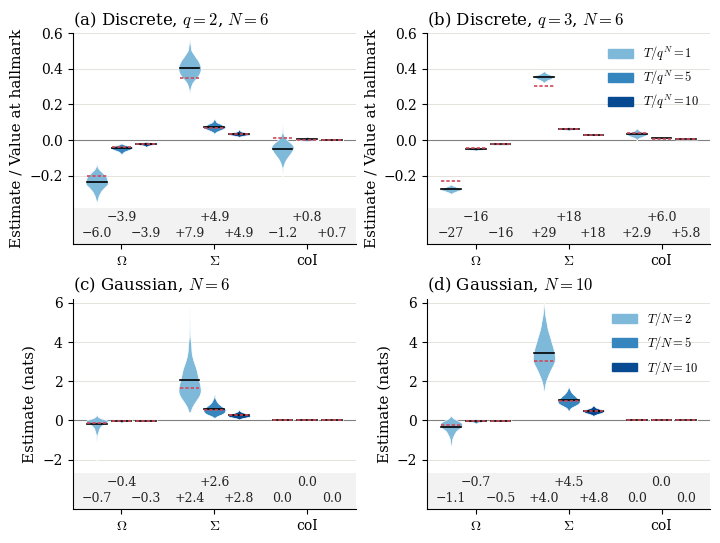

In [54]:
import matplotlib.transforms as mtr
from matplotlib.patches import Rectangle

def bias_figure(dsims, gsims, names, name, fs=12, ylims=None, strip=0.17):
    """ylims: data range of each row (the strip with mean/s.d. is added below it)."""
    ylims = ylims or {"d": (-0.38, 0.6), "g": (-2.7, 6.2)}
    cols = plt.cm.Blues(np.linspace(0.45, 0.9, 3)); w = 0.8 / 3
    fig, axes = plt.subplots(2, 2, figsize=(18 * cm, 13.5 * cm), constrained_layout=True)
    panels = [(axes[0, 0], "d", 2, r"(a) Discrete, $q=2$, $N=6$"), (axes[0, 1], "d", 3, r"(b) Discrete, $q=3$, $N=6$"),
              (axes[1, 0], "g", 6, r"(c) Gaussian, $N=6$"), (axes[1, 1], "g", 10, r"(d) Gaussian, $N=10$")]
    for ax, kind, p, title in panels:
        lo, hi = ylims[kind]
        ax.set_ylim(lo - strip / (1 - strip) * (hi - lo), hi)        # room for the strip below the data
        ax.add_patch(Rectangle((0, 0), 1, strip, transform=ax.transAxes, color="0.95", lw=0, zorder=0.6))
        ax.axhline(0, color="gray", lw=0.8, zorder=1)
        tr = mtr.blended_transform_factory(ax.transData, ax.transAxes)
        for j, r in enumerate((1, 5, 10) if kind == "d" else (2, 5, 10)):
            for i, n in enumerate(names):
                x = i + (j - 1) * w
                if kind == "d":
                    N, q = 6, p; T = r * q ** N; c = M.coeffs(n, N); v_ = dsims[(q, r)][n]
                    s = M.hallmark_scale(c, q); ex, lead = B.exact_bias(c, N, q, T), B.leading_bias(c, N, q, T)
                else:
                    N = p; T = r * N; c = M.coeffs(n, N); v_ = gsims[(N, r)][n]
                    s = 1.0; ex, lead = G.exact_bias(c, N, T), G.leading_bias(c, N, T)
                v = ax.violinplot(v_ / s, positions=[x], widths=w * 0.9, showextrema=False)
                for b in v["bodies"]: b.set_facecolor(cols[j]); b.set_edgecolor("white"); b.set_linewidth(0.5); b.set_alpha(1)
                ax.plot([x - w * 0.4, x + w * 0.4], [ex / s] * 2, color=INK, lw=1.2, zorder=4)
                ax.plot([x - w * 0.4, x + w * 0.4], [lead / s] * 2, color=FIRST, lw=1.2, ls=(0, (2, 1.2)), zorder=5)
                z = v_.mean() / v_.std()
                # two staggered rows (middle sample size up), so that neighbouring numbers never overlap
                ypos = strip * (0.56 if j == 1 else 0.12)
                lab = "0.0" if abs(z) < 0.05 else (f"{z:+.0f}" if abs(z) >= 10 else f"{z:+.1f}").replace("-", "\u2212")
                ax.text(x, ypos, lab, transform=tr,
                        ha="center", va="bottom", fontsize=fs - 3, color="0.15", zorder=3)
                print(f"{title[:3]} T={T:5d} {n:6s} mean {v_.mean():+.4f}  exact {ex:+.4f}  leading {lead:+.4f}  "
                      f"sd {v_.std():.4f}  mean/sd {z:+6.2f}")
        ax.set_xticks(range(len(names))); ax.set_xticklabels([M.LABEL[n] for n in names], fontsize=fs)
        ax.tick_params(labelsize=fs - 2)
        ax.set_title(title, loc="left", fontsize=fs)
        ax.grid(axis="y", color=GRID, lw=0.7); ax.set_axisbelow(True)
        for sp in ("top", "right"): ax.spines[sp].set_visible(False)
        ax.set_yticks([t for t in ax.get_yticks() if lo - 1e-9 <= t <= hi + 1e-9])   # no ticks inside the strip
    for a in axes[0]: a.set_ylabel("Estimate / Value at hallmark", fontsize=fs - 1)
    for a in axes[1]: a.set_ylabel("Estimate (nats)", fontsize=fs - 1)
    h = [plt.Rectangle((0, 0), 1, 1, color=c) for c in cols]
    axes[0, 1].legend(h, [r"$T/q^N=1$", r"$T/q^N=5$", r"$T/q^N=10$"], frameon=False, fontsize=fs - 3, loc="upper right")
    axes[1, 1].legend(h, [r"$T/N=2$", r"$T/N=5$", r"$T/N=10$"], frameon=False, fontsize=fs - 3, loc="upper right")
    save(fig, name, dpi=250)
    plt.show()

bias_figure(sims_main, gsims_main, ["Omega", "Sigma", "coI"], "Figure_4_Bias_measures")

N=6 T=  12 TC     mean +0.9177  exact +0.9392  sd 0.3454  mean/sd  +2.7
N=6 T=  12 DTC    mean +1.0874  exact +1.1257  sd 0.5311  mean/sd  +2.0
N=6 T=  12 Sigma  mean +2.0051  exact +2.0649  sd 0.8530  mean/sd  +2.4
N=6 T=  12 TSE    mean +1.1622  exact +1.1958  sd 0.4816  mean/sd  +2.4
N=6 T=  12 Omega  mean -0.1697  exact -0.1865  sd 0.2742  mean/sd  -0.6
N=6 T=  12 OmegaStar mean -0.0343  exact -0.0377  sd 0.0572  mean/sd  -0.6
N=6 T=  12 coI    mean +0.0008  exact +0.0005  sd 0.0169  mean/sd  +0.0
N=6 T=  30 TC     mean +0.2849  exact +0.2872  sd 0.1037  mean/sd  +2.7
N=6 T=  30 DTC    mean +0.2990  exact +0.3026  sd 0.1170  mean/sd  +2.6
N=6 T=  30 Sigma  mean +0.5839  exact +0.5898  sd 0.2184  mean/sd  +2.7
N=6 T=  30 TSE    mean +0.3405  exact +0.3439  sd 0.1271  mean/sd  +2.7
N=6 T=  30 Omega  mean -0.0142  exact -0.0154  sd 0.0348  mean/sd  -0.4
N=6 T=  30 OmegaStar mean -0.0028  exact -0.0031  sd 0.0070  mean/sd  -0.4
N=6 T=  30 coI    mean +0.0000  exact +0.0000  sd 0.0003  

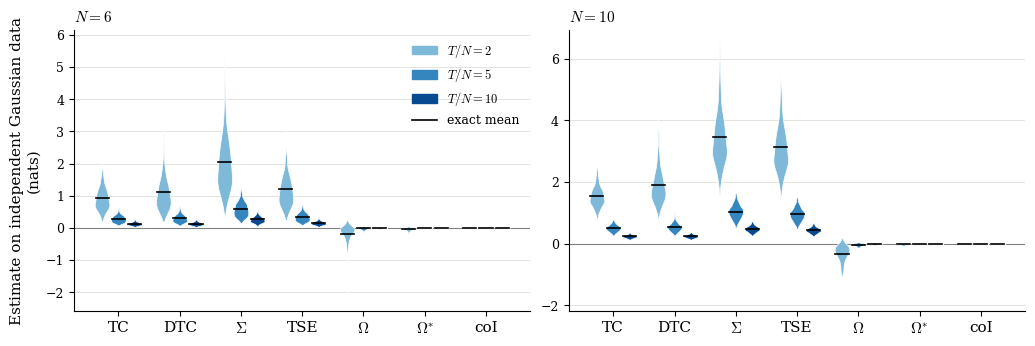

In [55]:
GSI = dict(names=["TC", "DTC", "Sigma", "TSE", "Omega", "OmegaStar", "coI"], Ns=(6, 10), ratios=(2, 5, 10))
gsims_SI = cached("gaussian_bias_SI", lambda: run_gauss(**GSI, R=600, seed=0))
gauss_figure(gsims_SI, **GSI, name="SI_Figure_4_More_gaussian_bias", width=26.0)

In [56]:
# SI Table S-gauss (separate run: Sigma and Omega only, 1000 data sets, seed 0)
gsims_tab = cached("tab_S-gauss", lambda: run_gauss(["Sigma", "Omega"], (6, 10), (2, 5, 10), R=1000, seed=0))
rows = []
for N in (6, 10):
    for ratio in (2, 5, 10):
        T = ratio * N; row = dict(N=N, T=T)
        for m in ("Sigma", "Omega"):
            s = gsims_tab[(N, ratio)][m]
            row.update({f"{m} exact": G.exact_bias(M.coeffs(m, N), N, T), f"{m} mean": s.mean(), f"{m} sd": s.std()})
        rows.append(row)
tabS_gauss = pd.DataFrame(rows)
save_table(tabS_gauss, "tab_S-gauss", floatfmt="%.4f")
print(tabS_gauss.round(4).to_string(index=False))

# 'its bias falls below one standard deviation once T exceeds about C(N,3)/4' (SI Eq. S-gauss-ratio3)
for N in (10, 20):
    print(f"N={N}: C(N,3)/4 = {comb(N, 3) / 4:.0f}")

 N   T  Sigma exact  Sigma mean  Sigma sd  Omega exact  Omega mean  Omega sd
 6  12       2.0649      2.0404    0.8637      -0.1865     -0.1812    0.2761
 6  30       0.5898      0.5835    0.2235      -0.0154     -0.0137    0.0364
 6  60       0.2704      0.2684    0.0965      -0.0032     -0.0032    0.0112
10  20       3.4581      3.5193    0.8830      -0.3506     -0.3573    0.3326
10  50       1.0380      1.0391    0.2319      -0.0319     -0.0303    0.0430
10 100       0.4816      0.4840    0.1010      -0.0069     -0.0070    0.0129
N=10: C(N,3)/4 = 30
N=20: C(N,3)/4 = 285


In [57]:
# SI 'Numerical check': the exact mean also holds for strongly correlated Gaussians (N=6, T=30, 2e4 data sets)
corr = pd.DataFrame(cached("gaussian_correlated_check", G.correlated_check))
print(corr.round(4).to_string(index=False))
print("max |z| =", corr["z"].abs().max().round(2), "; sd(Omega_hat) / sd for independent variables:",
      corr.loc[corr.measure == "Omega", "sd_ratio"].round(1).tolist())

 seed measure    bias   exact       z     sd  sd_ratio
    1      TC  0.2869  0.2872 -0.1431 0.2671    2.5549
    1     DTC  0.3037  0.3026  0.2455 0.6343    5.2167
    1   Sigma  0.5907  0.5898  0.1423 0.8256    3.6936
    1   Omega -0.0168 -0.0154 -0.3762 0.5154   13.5045
    1     coI  0.0010  0.0000  1.2033 0.1170  259.4700
    2      TC  0.2873  0.2872  0.0528 0.2237    2.1338
    2     DTC  0.3049  0.3026  0.6845 0.4725    3.8873
    2   Sigma  0.5922  0.5898  0.5106 0.6565    2.9330
    2   Omega -0.0176 -0.0154 -0.9166 0.3400    9.0006
    2     coI -0.0000  0.0000 -0.0354 0.0338   72.9600
    3      TC  0.2908  0.2872  1.7976 0.2861    2.7208
    3     DTC  0.3106  0.3026  2.0936 0.5348    4.3587
    3   Sigma  0.6014  0.5898  2.1452 0.7617    3.3817
    3   Omega -0.0197 -0.0154 -1.5350 0.3945   10.2184
    3     coI -0.0014  0.0000 -1.1107 0.1776  334.6842
max |z| = 2.15 ; sd(Omega_hat) / sd for independent variables: [13.5, 9.0, 10.2]


## 7. Dyadic and triadic distributions (SI Tables S-dt and S-dt-family)

Three variables with $q=4$ states (James and Crutchfield 2017). Both distributions have the same subset entropies, but their Fourier components occupy different directions of $\mathbb Z_4^3$. Along a one-parameter family of full-support distributions, a triadic member with $\kappa_{XYZ}=0$ has all its subset entropies equal to those of a dyadic member.

In [58]:
rows = []
for kind in ("dyadic", "triadic"):
    P = dyadic.endpoint(kind)
    comps = dyadic.z4_components(P)
    print(kind, "| entropies (bits):", np.round(dyadic.entropies(P) / dyadic.LN2, 6))
    for w in (2, 3):
        sel = [(r, v) for ww, r, v in comps if ww == w]
        rows.append(dict(distribution=kind, weight=w, directions=len(sel),
                         sum_rho2=round(sum(v for r, v in sel), 6),
                         rho2_values=sorted({round(v, 6) for r, v in sel}),
                         list=(", ".join("".join(map(str, r)) for r, v in sel) if len(sel) <= 8 else "")))
tabS_dt = pd.DataFrame(rows)
save_table(tabS_dt, "tab_S-dt")
print(tabS_dt.to_string(index=False))

dyadic | entropies (bits): [2. 2. 2. 3. 3. 3. 3.]
triadic | entropies (bits): [2. 2. 2. 3. 3. 3. 3.]
distribution  weight  directions  sum_rho2   rho2_values                                   list
      dyadic       2           6       3.0         [0.5]           012, 032, 120, 201, 203, 320
      dyadic       3          20       4.0 [0.125, 0.25]                                       
     triadic       2           3       3.0         [1.0]                          022, 202, 220
     triadic       3           8       4.0         [0.5] 111, 113, 131, 133, 311, 313, 331, 333


In [59]:
rows = []
for J3 in (0.3, 1.0, 2.0):
    J2, J = dyadic.indistinguishable_pair(J3)
    ht = dyadic.entropies(dyadic.maxent("triadic", J2, J3)); hd = dyadic.entropies(dyadic.maxent("dyadic", J))
    rows.append(dict(J3=J3, J2=J2, J=J, pair_bits=ht[3] / dyadic.LN2, triple_bits=ht[6] / dyadic.LN2,
                     max_entropy_difference=np.abs(ht - hd).max()))
tabS_family = pd.DataFrame(rows)
save_table(tabS_family, "tab_S-dt-family", floatfmt="%.4f")
print(tabS_family.round(4).to_string(index=False))

 J3     J2      J  pair_bits  triple_bits  max_entropy_difference
0.3 0.3248 0.4236     3.8813       5.6440                     0.0
1.0 0.7367 1.1524     3.4389       4.3167                     0.0
2.0 1.2559 2.1685     3.0995       3.2985                     0.0


## Output files

All figures are in `figures/` and all tables in `tables/`. The file names of the figures match those used in the LaTeX sources, except the slice figures: `Full_kite` and `Zoom_in` are panels (b) and (c) of Fig. 3, and `Curvature_phi_q_3_panels` contains the computed panels of the SI slice figure (the published figures add a schematic panel).

In [60]:
for d in (FIGURES, TABLES):
    print(d.name + "/:", ", ".join(sorted(p.name for p in d.iterdir())))

figures/: .ipynb_checkpoints, Figure_2_some_orderweights.pdf, Figure_2_some_orderweights.png, Figure_3_b.pdf, Figure_3_b.png, Figure_3_c.pdf, Figure_3_c.png, Figure_4_Bias_measures.pdf, Figure_4_Bias_measures.png, Figure_5_Mixing_vs_maxent.pdf, Figure_5_Mixing_vs_maxent.png, Figure_6_Fourier_decomposition_some_rules.pdf, Figure_6_Fourier_decomposition_some_rules.png, SI_Figure_2_More_bias_measure.pdf, SI_Figure_2_More_bias_measure.png, SI_Figure_3_Bias_saturation.pdf, SI_Figure_3_Bias_saturation.png, SI_Figure_4_More_gaussian_bias.pdf, SI_Figure_4_More_gaussian_bias.png
tables/: Tab_1_characters.csv, Tab_1_characters.tex, tab_S-autocorr.csv, tab_S-autocorr.tex, tab_S-beta.csv, tab_S-beta.tex, tab_S-bias.csv, tab_S-bias.tex, tab_S-dt-family.csv, tab_S-dt-family.tex, tab_S-dt.csv, tab_S-dt.tex, tab_S-gauss.csv, tab_S-gauss.tex, tab_S-marginals.csv, tab_S-marginals.tex
